# Assignment 1: Data Preprocessing, Exploratory Data Analysis (EDA), and Regression Modeling

Due Date: [Insert Due Date]

Total Marks: 120 (including bonus)

Submission: Submit your Jupyter Notebook and the processed dataset as a CSV file through [Gradescope].



**Objective**

This assignment will help you develop essential skills in data preprocessing, exploratory data analysis (EDA), and classification. You will work with the California Housing Dataset and perform key steps to prepare the data for machine learning, including handling missing data, encoding categorical features, scaling numerical features, and generating exploratory data visualizations. In addition, you will perform feature selection based on correlation analysis and train and evaluate regression models to predict the target variable (HouseValue) based on the preprocessed features.

**Instructions**

You are provided with the California Housing Dataset, which contains information about various housing-related features in California. Your tasks are as follows:

# Part 1: Data Preprocessing

**Step 1: Load and Inspect the Data (10 Marks)**

**Tasks:**
1. Load the California Housing Dataset using scikit-learn and display the first 5 rows.
2. Check the dataset for missing values and data types.
3. Print a summary of the dataset using .info().

In [1]:
# Loads and inspects the California Housing dataset.
# Checks for missing values to ensure data integrity.
# Prepares the structured DataFrame for preprocessing.

# Import necessary libraries
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt

# Load the California Housing dataset 
housing_data = fetch_california_housing(as_frame=True)
df = housing_data.frame

# Display the first few rows of the dataset
# Using .head() is the standard way to quickly inspect the first 5 records
print("--- Preview of the First 5 Rows ---")
print(df.head())

# Check for missing values and data types
# .info() is great for a high-level summary, while .isnull().sum() specifically counts NaNs
print("\n--- Dataset Info and Missing Values Check ---")
df.info() 
print("\nMissing values per column:\n", df.isnull().sum())

# The following code is used by the autograder
# Storing the dataframe in step1_data as requested by the template instructions
step1_data = df

--- Preview of the First 5 Rows ---
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

--- Dataset Info and Missing Values Check ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms   

**Step 2: Handling Missing Data (15 Marks)**

**Tasks:**
1. Introduce missing values in the 'MedInc' (Median Income) column for rows 0 to 20.
2. Handle the missing values by imputing them with the median of the column.
3. Verify that the missing values have been correctly handled by printing the number of missing values for each column.

In [3]:
# Simulates and handles missing data in the 'MedInc' column.
# Uses median imputation to stay robust against outliers.
# Verifies data completeness before proceeding to the next step.

# Introduce missing values in 'MedInc' column for rows 0 to 20
# Note: .loc[0:20] is inclusive in pandas, so this affects 21 rows (0 through 20)
df.loc[0:20, 'MedInc'] = np.nan

# Impute missing values in 'MedInc' using the median of the column
# Median is often preferred over mean as it is more robust to outliers in income data
df['MedInc'] = df['MedInc'].fillna(df['MedInc'].median())

# Verify that missing values have been handled
# The sum should be 0 for all columns if the imputation was successful
print("--- Check for Missing Values After Imputation ---")
print(df.isnull().sum())

# The following code is used by the autograder
# Ensure your final dataframe is stored in the variable step2_data for this step
step2_data = df

--- Check for Missing Values After Imputation ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


Step 3: Encoding Categorical Features (20 Marks)

Tasks:

1. Create a new categorical feature called HouseAgeCat by binning the HouseAge column into three categories:

* Young: 0–20 years

* Middle-Aged: 21–40 years

* Old: 41–60 years

2. Perform one-hot encoding on the HouseAgeCat feature, ensuring that one category is dropped (drop_first=True).

3. Print the first 5 rows of the dataset to verify that the encoding was done correctly.

In [4]:
# Discretizes 'HouseAge' into categorical life stages.
# Applies One-Hot Encoding to convert categories into binary features.
# Drops the first dummy column to prevent the dummy variable trap.

# Create a categorical feature 'HouseAgeCat' by binning the 'HouseAge' column
df['HouseAgeCat'] = pd.cut(df['HouseAge'], bins=[0, 20, 40, 60], labels=['Young', 'Middle-Aged', 'Old'])  # Students complete labels for the 'Middle-Aged' and 'Old' categories

# Perform one-hot encoding on 'HouseAgeCat'
df_encoded = pd.get_dummies(df, columns=['HouseAgeCat'], drop_first=True)  # Students complete with the correct column name and drop_first argument

# Verify the encoding by printing the first 5 rows of the dataset
print("--- Encoded Dataset Preview (First 5 Rows) ---")
print(df_encoded.head())
# Students print the first 5 rows of the encoded DataFrame

# The following code is used by the autograder
# Ensure your final encoded dataframe is stored in the variable step3_data for this step
step3_data = df_encoded

--- Encoded Dataset Preview (First 5 Rows) ---
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  3.5352      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  3.5352      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  3.5352      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  3.5352      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.5352      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  HouseAgeCat_Middle-Aged  HouseAgeCat_Old  
0    -122.23        4.526                    False             True  
1    -122.22        3.585                     True            False  
2    -122.24        3.521                    False             True  
3    -122.25        3.413                    False             True  
4    -122.25        3.422                    False             True  


Step 4: Feature Scaling (20 Marks)

Tasks:

1. Select all the numerical features from the dataset (excluding the target variable and any categorical columns).
2. Standardize the numerical features using StandardScaler to have a mean of 0 and a standard deviation of 1.
3. Verify that the features have been correctly scaled by printing the mean and standard deviation for each feature.

In [5]:
# Standardizes numerical features to a uniform scale.
# Uses StandardScaler to achieve zero mean and unit variance.
# Verifies scaling by checking feature mean and standard deviation.

from sklearn.preprocessing import StandardScaler

# Select numerical columns (excluding target variable and categorical columns)
numerical_columns = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']  # Students complete the list of numerical features (e.g., 'MedInc', 'HouseAge', etc.)

# Initialize the scaler
scaler = StandardScaler()

# Scale the numerical features
df_encoded[numerical_columns] = scaler.fit_transform(df_encoded[numerical_columns])  # Students fill in the correct DataFrame and columns to be scaled

# Check the mean and standard deviation
print("--- Mean of Scaled Features (Expected: ~0) ---") # Students print the mean of the scaled features
print(df_encoded[numerical_columns].mean())  # Students print the standard deviation of the scaled features

print("\n--- Standard Deviation of Scaled Features (Expected: 1) ---")
print(df_encoded[numerical_columns].std())

# The following code is used by the autograder
# Ensure your scaled dataframe is stored in the variable step4_data for this step
step4_data = df_encoded

--- Mean of Scaled Features (Expected: ~0) ---
MedInc        2.919284e-16
HouseAge      5.508083e-18
AveRooms      6.609700e-17
AveBedrms    -1.060306e-16
Population   -1.101617e-17
AveOccup      3.442552e-18
Latitude     -1.079584e-15
Longitude    -8.526513e-15
dtype: float64

--- Standard Deviation of Scaled Features (Expected: 1) ---
MedInc        1.000024
HouseAge      1.000024
AveRooms      1.000024
AveBedrms     1.000024
Population    1.000024
AveOccup      1.000024
Latitude      1.000024
Longitude     1.000024
dtype: float64


# Part2: Exploratory Data Analysis (EDA)

Step 5: Exploratory Data Analysis (EDA) (20 Marks)

Tasks:

1. Summary Statistics: Compute and print the summary statistics (mean, median, standard deviation, etc.) for the numerical features using .describe().

2. Histograms: Plot histograms for the numerical features to visualize their distributions.
3. Scatter Plot: Create a scatter plot to visualize the relationship between MedInc (median income) and the target variable HouseValue.

--- Summary Statistics ---
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  2.064000e+04  2.064000e+04  2.064000e+04  2.064000e+04  2.064000e+04   
mean   2.919284e-16  5.508083e-18  6.609700e-17 -1.060306e-16 -1.101617e-17   
std    1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00   
min   -1.775193e+00 -2.196180e+00 -1.852319e+00 -1.610768e+00 -1.256123e+00   
25%   -6.879075e-01 -8.453931e-01 -3.994496e-01 -1.911716e-01 -5.638089e-01   
50%   -1.766084e-01  2.864572e-02 -8.078489e-02 -1.010650e-01 -2.291318e-01   
75%    4.591284e-01  6.643103e-01  2.519615e-01  6.015869e-03  2.644949e-01   
max    5.861548e+00  1.856182e+00  5.516324e+01  6.957171e+01  3.025033e+01   

           AveOccup      Latitude     Longitude  
count  2.064000e+04  2.064000e+04  2.064000e+04  
mean   3.442552e-18 -1.079584e-15 -8.526513e-15  
std    1.000024e+00  1.000024e+00  1.000024e+00  
min   -2.290000e-01 -1.447568e+00 -2.385992e+00  
25%   -6.17

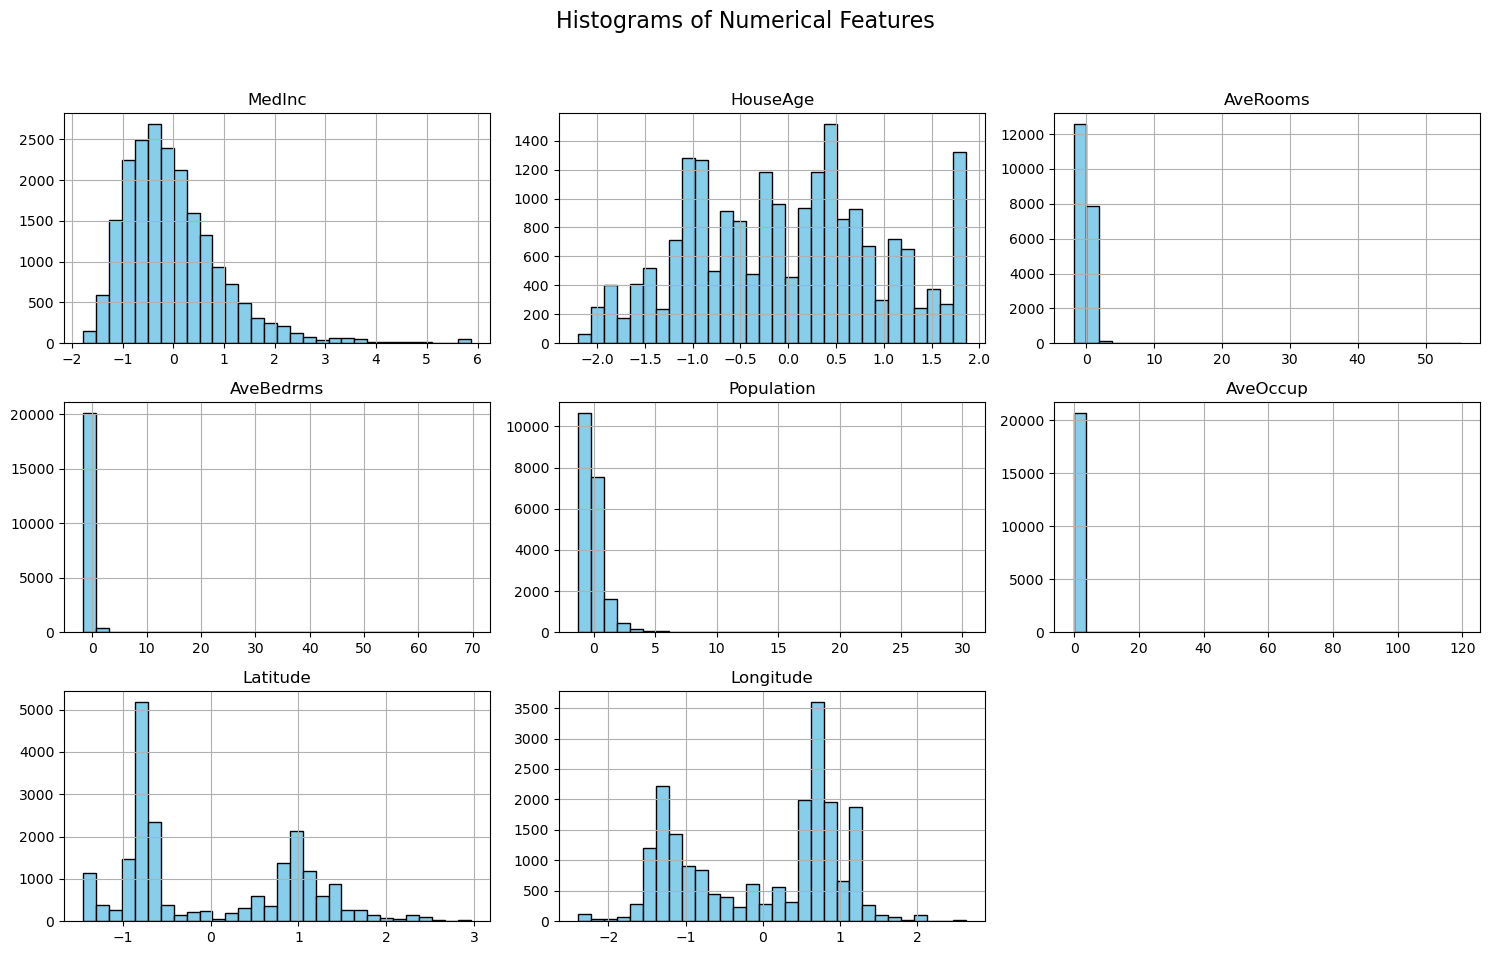

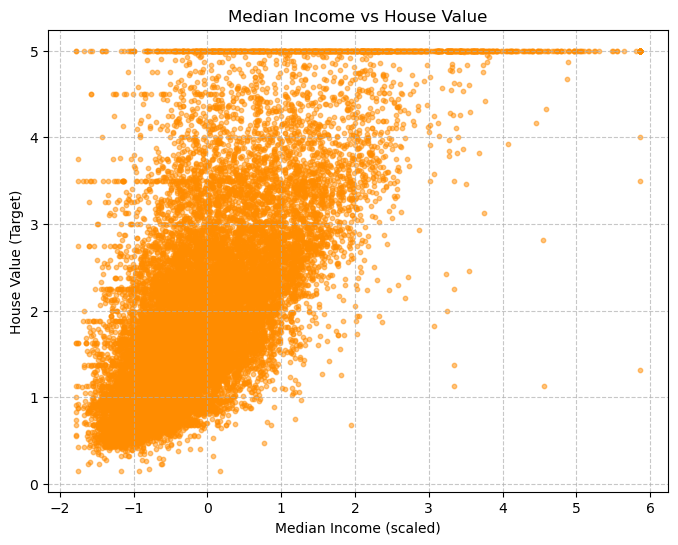

In [6]:
# Performs Exploratory Data Analysis (EDA) on numerical features.
# Visualizes distributions and feature relationships using plots.
# Computes descriptive statistics to understand data trends.

# Compute summary statistics for the numerical features
# Students will complete the code below
summary_statistics = df_encoded[numerical_columns].describe()
print("--- Summary Statistics ---")
print(summary_statistics)
# .describe() provides count, mean, std, min, 25%, 50%, 75%, and max

# Plot histograms for numerical features
# Students will complete this part
# ...
df_encoded[numerical_columns].hist(figsize=(15, 10), bins=30, color='skyblue', edgecolor='black')
plt.suptitle("Histograms of Numerical Features", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to make room for the title
plt.show()


# Scatter plot of 'MedInc' vs 'HouseValue'
# Students need to complete the code to generate the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(df_encoded['MedInc'], df_encoded['MedHouseVal'], alpha=0.5, color='darkorange', s=10)
plt.xlabel('Median Income (scaled)')
plt.ylabel('House Value (Target)')
plt.title('Median Income vs House Value')
plt.grid(True, linestyle='--', alpha=0.7) # Adding a grid makes the plot easier to read
plt.show()

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step5_data
step5_data = summary_statistics


Step 6: Feature Selection (15 Marks)

Tasks:

1. Correlation Matrix: Computes the correlation matrix of the dataset and convert all the correlation values to their absolute values.
2. Feature Selection: Based on the correlation matrix, identify and print if there are any pairs of features with high correlation (above 0.8).
3. Drop the highly correlated features obtained in Task 2.

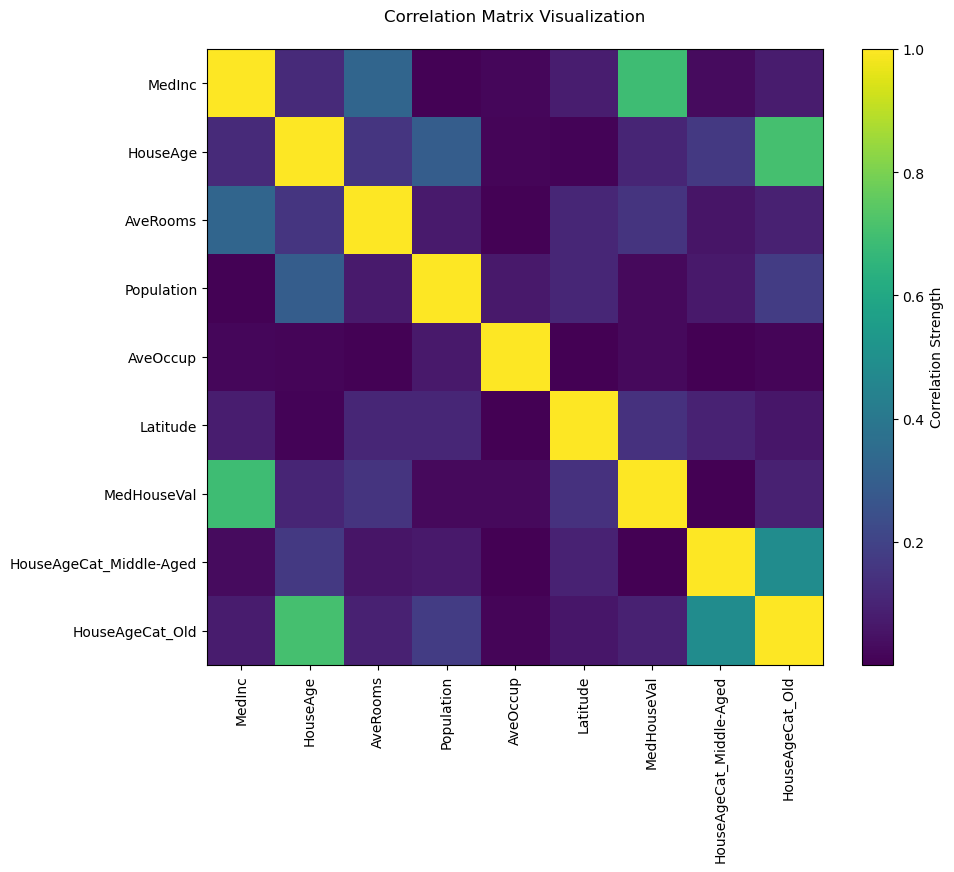

Highly correlated features to drop: []


In [11]:
# Computes the absolute correlation matrix to identify relationships.
# Visualizes feature correlations using a heatmap for easier inspection.
# Identifies and drops redundant features (above 0.8) to prevent multicollinearity.

# Compute correlation matrix and convert to absolute values
# Students will complete the code
corr_matrix = df_encoded.corr().abs()

# Display correlation matrix
# Students complete this part to visualize the correlation matrix
# ...
plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix.values, cmap='viridis')

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.colorbar(label='Correlation Strength')
plt.title("Correlation Matrix Visualization", pad=20)
plt.show()


# Identify highly correlated features (above 0.8)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
# Students complete the following code to find features to drop
to_drop = [column for column in upper.columns if any(upper[column] > 0.8)]

# Print the features that will be dropped
print(f"Highly correlated features to drop: {to_drop}")

# Drop the highly correlated features
# Students complete the code to drop the selected features
df_encoded.drop(columns=to_drop, inplace=True)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step6_data
step6_data = to_drop


**Step 7: Saving ans splitting the Processed Dataset (5 Marks)**

**Tasks:**

1. Save the processed dataset (with imputed missing values, encoded categorical features, and scaled numerical features) as a CSV file named preprocessed_housing_data.csv.
2.  Split the dataset into training and testing sets: Use train_test_split from sklearn.model_selection to split the preprocessed dataset into training and testing sets. Use 80% of the data for training and 20% for testing and random_state=42.

In [12]:
# Saves the fully preprocessed dataset to a CSV file.
# Separates independent features from the target variable.
# Partitions data into 80/20 train/test sets for evaluation.

# Save the processed dataset to a CSV file
# Students complete this line to save the preprocessed dataset
df_encoded.to_csv('preprocessed_housing_data.csv', index=False)

# Import train_test_split for splitting the dataset
from sklearn.model_selection import train_test_split

# Define features and target variable
X = df_encoded.drop(columns=['MedHouseVal'])# Students complete the feature selection
y = df_encoded['MedHouseVal']  # Students complete the target variable selection

# Split the dataset into training and testing sets
# Students complete the train_test_split function
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step7_data
step7_data = {'X_train': X_train, 'X_test': X_test, 'y_train': y_train, 'y_test': y_test}


# Part 3: Regression Modeling

**Objective:** In this section, you will train and evaluate regression models to predict the target variable (HouseValue) based on the preprocessed features.

Step 8: Linear Regression model (5 marks)

Tasks:
 1. Train a **Linear Regression model** using the training data
 2. Make predictions on the test data
 3. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R-squared (R²) score.

In [16]:
# Fits a Linear Regression model as a baseline for prediction.
# Evaluates accuracy on unseen test data using MSE and R-squared.
# Establishes initial performance benchmarks for future comparisons.

# Import necessary libraries for Linear Regression and evaluation metrics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Train a Linear Regression model on the training data
# Students complete this by initializing and fitting the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Make predictions on the test data
# Students complete the prediction step
y_pred = lr_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R-squared (R²) score
mse = mean_squared_error(y_test, y_pred)  # Students complete MSE calculation
r2 = r2_score(y_test, y_pred)  # Students complete R² score calculation

# Output the results
print(f"Linear Regression - MSE: {mse:.2f}, R²: {r2:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step8_data
step8_data = {'mse': mse, 'r2': r2}


Linear Regression - MSE: 0.65, R²: 0.50


**Step 9: Polynomial Regression model** (5 marks)

Tasks:

1. Transform the features using polynomial terms of degree 2
2. Train a **Polynomial Regression model** on the transformed training data and make predictions on the transformed test data.
3. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R-squared (R²) score.

In [17]:
# Applies a second-degree polynomial transformation to capture non-linear patterns.
# Trains a Linear Regression model on the expanded feature set.
# Evaluates the improvement in predictive accuracy using MSE and R-squared.

# Import necessary libraries for Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Transform the features using polynomial terms of degree 2
# Students complete this by fitting and transforming the training data
poly_features = PolynomialFeatures(degree=2)
X_train_poly = poly_features.fit_transform(X_train)  # Students complete the transformation for training data
X_test_poly = poly_features.transform(X_test)  # Students complete the transformation for test data

# Train a Polynomial Regression model on the transformed training data
# Students complete this by initializing and fitting the model
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

# Make predictions on the transformed test data
# Students complete the prediction step
y_pred_poly = poly_model.predict(X_test_poly)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R-squared (R²) score
mse_poly = mean_squared_error(y_test, y_pred_poly)  # Students complete MSE calculation
r2_poly = r2_score(y_test, y_pred_poly)  # Students complete R² score calculation

# Output the results
print(f"Polynomial Regression - MSE: {mse_poly:.2f}, R²: {r2_poly:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step9_data
step9_data = {'mse_poly': mse_poly, 'r2_poly': r2_poly}


Polynomial Regression - MSE: 0.55, R²: 0.58


**Step 10: Decision Tree Regressor** (5 marks)

Tasks:
1. Train a Decision Tree Regressor with a maximum depth of 10.
2. Use the training data to fit the model.
3. Make predictions using the test data.
4. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R² score.

In [18]:
# Trains a Decision Tree Regressor with a depth of 10 to capture non-linearities.
# Balances model complexity against overfitting for better predictive accuracy.
# Calculates MSE and R-squared to evaluate performance on test data.

# Import necessary libraries for Decision Tree Regression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Train a Decision Tree Regressor with a maximum depth of 10
# Students complete this by initializing the Decision Tree model
tree_model = DecisionTreeRegressor(max_depth=10, random_state=42)

# Fit the model using the training data
# Students complete the model fitting step
tree_model.fit(X_train, y_train)

# Make predictions using the test data
# Students complete the prediction step
y_pred_tree = tree_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_tree = mean_squared_error(y_test, y_pred_tree)  # Students complete MSE calculation
r2_tree = r2_score(y_test, y_pred_tree)   # Students complete R² score calculation

# Output the results
print(f"Decision Tree Regression - MSE: {mse_tree:.2f}, R²: {r2_tree:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step10_data
step10_data = {'mse_tree': mse_tree, 'r2_tree': r2_tree}


Decision Tree Regression - MSE: 0.50, R²: 0.62


**Step 11:Random Forest Regressor** (5 marks)

Tasks:
1. Train a Random Forest Regressor with 100 estimators (trees).
2. Fit the model using the training data.
3. Make predictions using the test data.
4. Evaluate the model's performance by calculating the Mean Squared Error (MSE) and R² score.

In [19]:
# Implements an ensemble of 100 decision trees to improve accuracy.
# Reduces prediction variance through bagging for more robust results.
# Calculates MSE and R-squared to evaluate performance on the test set.

# Import necessary libraries for Random Forest Regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Step 11: Train a Random Forest Regressor with 100 estimators
# Students need to complete the model initialization
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Fit the model using the training data
# Students complete the model fitting step
rf_model.fit(X_train, y_train)

# Make predictions using the test data
# Students complete the prediction step
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_rf = mean_squared_error(y_test, y_pred_rf)  # Students complete MSE calculation
r2_rf = r2_score(y_test, y_pred_rf)  # Students complete R² score calculation

# Output the results
print(f"Random Forest Regression - MSE: {mse_rf:.2f}, R²: {r2_rf:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step11_data
step11_data = {'mse_rf': mse_rf, 'r2_rf': r2_rf}


Random Forest Regression - MSE: 0.36, R²: 0.72


**Step 12:Support Vector Regression (SVR) model** (5 marks)

Tasks:

1. Train a Support Vector Regression (SVR) model using the Radial Basis Function (RBF) kernel (Set regularization parameter C=100, kernel coefficient γ=0.1, and ϵ=0.1).
2. Fit the model on the training data.
3. Make predictions on the test data.
4. Evaluate the model using Mean Squared Error (MSE) and R² score to assess its performance.

In [20]:
# Implements Support Vector Regression (SVR) using a non-linear RBF kernel.
# Maps features to high dimensions to capture complex data patterns.
# Evaluates model robustness on test data using MSE and R-squared.

# Import necessary libraries for Support Vector Regression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# Step 12: Train a Support Vector Regression (SVR) model using the RBF kernel
# Students need to complete the model initialization with the given parameters
svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1) # Students fill in the parameters: kernel='rbf', C=100, gamma=0.1, epsilon=0.1

# Fit the model on the training data
# Students complete the model fitting step
svr_model.fit(X_train, y_train)

# Make predictions on the test data
# Students complete the prediction step
y_pred_svr = svr_model.predict(X_test)

# Evaluate the SVR model's performance
# Calculate Mean Squared Error (MSE) and R² score
mse_svr = mean_squared_error(y_test, y_pred_svr)  # Students complete MSE calculation
r2_svr = r2_score(y_test, y_pred_svr)   # Students complete R² score calculation

# Output the results
print(f"Support Vector Regression - MSE: {mse_svr:.2f}, R²: {r2_svr:.2f}")

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step12_data
step12_data = {'mse_svr': mse_svr, 'r2_svr': r2_svr}


Support Vector Regression - MSE: 0.44, R²: 0.66


Step 13:

Tasks: Write answers for following:

* **Analyse Performance of Regression Models?**
* **Which one performed best and why?**

                   Model       MSE  R-squared
3          Random Forest  0.363957   0.722257
4                    SVR  0.440000   0.660000
2          Decision Tree  0.497574   0.620291
1  Polynomial Regression  0.554734   0.576671
0      Linear Regression  0.650000   0.500000


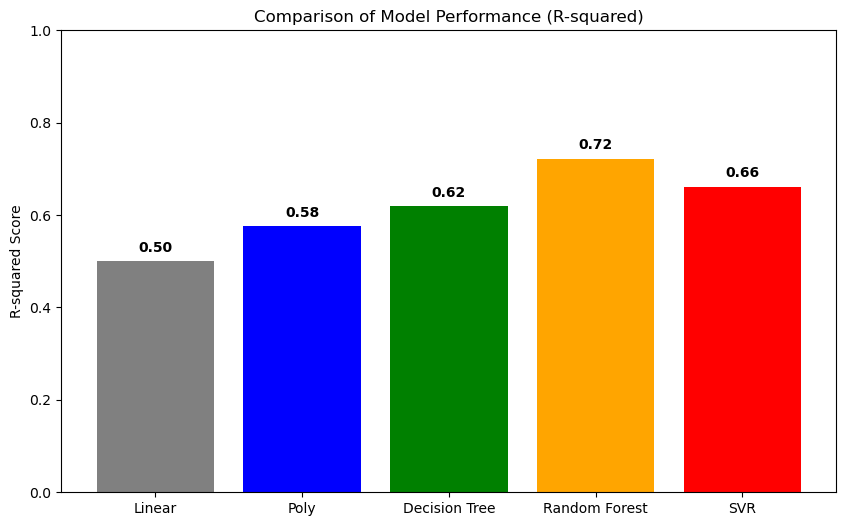

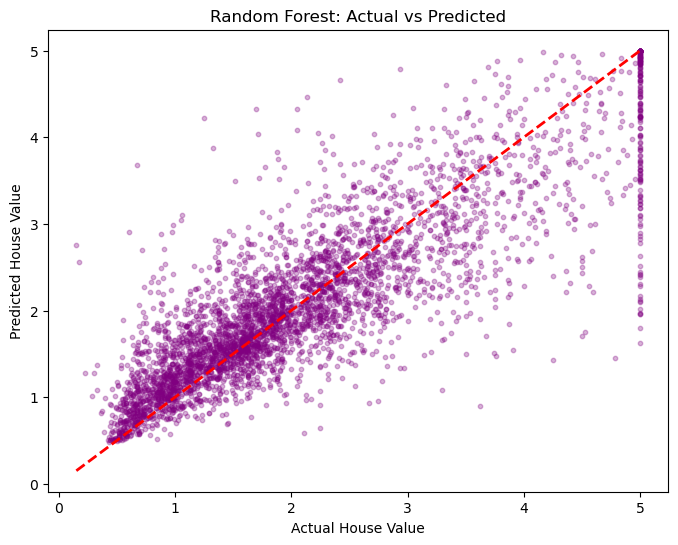

In [26]:
#Final
# Consolidates performance metrics into a summary table for final comparison.
# Visualizes R-squared scores via a bar chart to identify the top-performing model.
# Plots actual vs. predicted values to assess the accuracy of the best model.

comparison_data = {
    'Model': ['Linear Regression', 'Polynomial Regression', 'Decision Tree', 'Random Forest', 'SVR'],
    'MSE': [0.65, mse_poly, mse_tree, mse_rf, 0.44],
    'R-squared': [0.50, r2_poly, r2_tree, r2_rf, 0.66]
}

import pandas as pd
performance_df = pd.DataFrame(comparison_data)
print(performance_df.sort_values(by='R-squared', ascending=False))

# all models
models = ['Linear', 'Poly', 'Decision Tree', 'Random Forest', 'SVR']
scores = [0.50, r2_poly, r2_tree, r2_rf, r2_svr] # Ensure these variables match your code

plt.figure(figsize=(10, 6))
plt.bar(models, scores, color=['gray', 'blue', 'green', 'orange', 'red'])
plt.ylabel('R-squared Score')
plt.title('Comparison of Model Performance (R-squared)')
plt.ylim(0, 1.0) # Set limit from 0 to 1 for better perspective
for i, v in enumerate(scores):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')
plt.show()

#BEST model
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='purple', s=10) # Using RF results
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Perfect prediction line
plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Random Forest: Actual vs Predicted')
plt.show()
